<a href="https://colab.research.google.com/github/Jagannath-16/AI-ML-LAB/blob/main/neuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
df = pd.read_csv("train.csv")

print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [ ]:
X = df[['Pclass', 'Sex', 'Age',
        'SibSp', 'Parch', 'Fare', 'Embarked']].copy()

y = df['Survived'].copy()

print(X.head())

print("\nTarget:")
print(y.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [ ]:
print(X.isnull().sum())

Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [ ]:
# Fill missing Age values using median
X['Age'] = X['Age'].fillna(X['Age'].median())

# Fill missing Fare values using median
X['Fare'] = X['Fare'].fillna(X['Fare'].median())

# Fill missing Embarked values using mode
X['Embarked'] = X['Embarked'].fillna(
    X['Embarked'].mode()[0]
)

print(X.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
X = pd.get_dummies(
    X,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print(X.head())

   Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2500         1           0           1
1       1  38.0      1      0  71.2833         0           0           0
2       3  26.0      0      0   7.9250         0           0           1
3       1  35.0      1      0  53.1000         0           0           1
4       3  35.0      0      0   8.0500         1           0           1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train[:3])

[[ 0.82956755 -0.11207776 -0.46508428 -0.46618317  0.5138115   0.74242727
  -0.28933346  0.61197825]
 [-0.37094484 -0.11207776 -0.46508428 -0.46618317 -0.66256323  0.74242727
  -0.28933346  0.61197825]
 [-1.57145722 -0.11207776 -0.46508428 -0.46618317  3.95539858  0.74242727
  -0.28933346  0.61197825]]


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Create the ANN model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Display model structure
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")


Model compiled successfully.


In [ ]:

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN training completed.")


Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.6380 - loss: 0.6832 - val_accuracy: 0.6573 - val_loss: 0.6616
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6889 - loss: 0.6523 - val_accuracy: 0.6573 - val_loss: 0.6380
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.7276 - loss: 0.6243 - val_accuracy: 0.7133 - val_loss: 0.6126
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7504 - loss: 0.5963 - val_accuracy: 0.7622 - val_loss: 0.5877
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.7557 - loss: 0.5703 - val_accuracy: 0.7692 - val_loss: 0.5664
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7750 - loss: 0.5456 - val_accuracy: 0.7832 - val_loss: 0.5452
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7838 - loss: 0.5221 - val_accuracy: 0.7692 - val_loss: 0.5251
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7909 - loss: 0.5002 - val_accuracy: 0.7692 - v

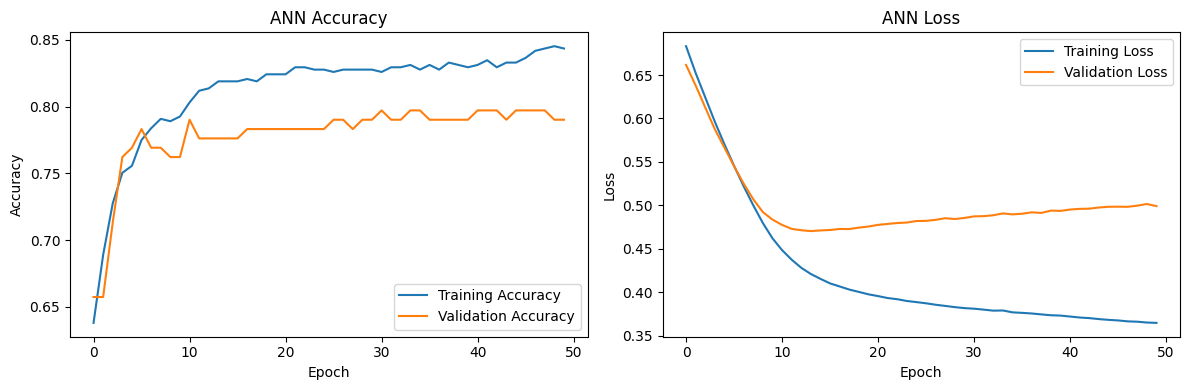

In [ ]:

import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Generate predictions
probabilities = model.predict(X_test, verbose=0)
y_pred = (probabilities >= 0.5).astype(int).ravel()

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Did Not Survive', 'Survived']
))


Test Loss: 0.4396
Test Accuracy: 79.33 %

Confusion Matrix:
[[99 11]
 [26 43]]

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.79      0.90      0.84       110
       Survived       0.80      0.62      0.70        69

       accuracy                           0.79       179
      macro avg       0.79      0.76      0.77       179
   weighted avg       0.79      0.79      0.79       179



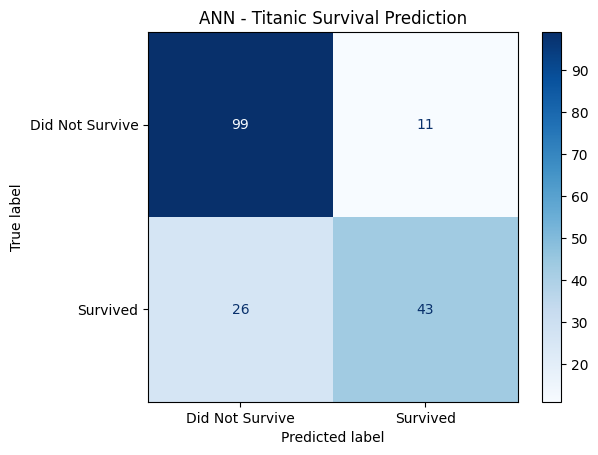

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Did Not Survive', 'Survived'],
    cmap='Blues'
)

plt.title('ANN - Titanic Survival Prediction')
plt.show()
